# Bagian D - Model pembanding: DeepLabV3 + ResNet-50
Fine-tuning **DeepLabV3 + ResNet-50** (pretrained COCO) ke **11 kelas CamVid**, lalu dibandingkan dengan
model utama **DeepLabV3 + MobileNetV3-Large** (`camvid_train.ipynb`).

Supaya perbandingannya adil, semua pengaturan **sama** dengan `camvid_train.ipynb`: pemetaan 11 kelas,
bobot kelas median frequency, ukuran 360x480, augmentasi flip, batch 8, 50 epoch, AdamW lr 5e-4,
cosine annealing, seed 0, dan model terbaik dipilih dari mIoU validasi. Yang berbeda hanya:

| | MobileNetV3 (`camvid_train.ipynb`) | ResNet-50 (notebook ini) |
|---|---|---|
| backbone | MobileNetV3-Large (ringan, untuk perangkat mobile) | ResNet-50 (lebih dalam & lebar) |
| output stride | 16 | 8 (peta fitur 2x lebih rapat) |
| presisi training | float32 | mixed precision (float16) supaya batch 8 muat di GPU 8 GB |
| bobot di file model | float32 (42 MB) | float16 (sekitar 76 MB, di bawah batas file GitHub 100 MB) |

Evaluasi kedua model tetap memakai float32.

**Lokal**: dataset di `data/CamVid/`, buka notebook ini dari `src/semantic_segmentation/`, *Run All*.
Model tersimpan di `model/camvid_deeplabv3_r50.pth`, hasil perbandingan di `results/semantic_compare/`.

Alur: data -> pemetaan 32 kelas ke 11 kelas -> fine-tuning -> evaluasi data test -> perbandingan dengan MobileNetV3.

In [1]:
import os, glob, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

# seed supaya hasil training bisa diulang
random.seed(0); np.random.seed(0); torch.manual_seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
if device.type == 'cpu':
    print('PERINGATAN: GPU tidak terdeteksi, training di CPU akan sangat lambat')

device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Konfigurasi

In [2]:
# lokasi dataset & tempat menyimpan model
found = glob.glob('/kaggle/input/**/class_dict.csv', recursive=True)
if found:
    # di Kaggle: folder input bisa beda-beda namanya, jadi dicari dari letak class_dict.csv
    DATA_ROOT = os.path.dirname(found[0])
    OUT_PATH  = '/kaggle/working/camvid_deeplabv3_r50.pth'
    CMP_DIR   = '/kaggle/working/semantic_compare'
else:
    # lokal: notebook ada di src/semantic_segmentation/, dataset di data/CamVid/ (root repo)
    DATA_ROOT = os.path.join('..', '..', 'data', 'CamVid')
    OUT_PATH  = os.path.join('model', 'camvid_deeplabv3_r50.pth')
    CMP_DIR   = os.path.join('..', '..', 'results', 'semantic_compare')
    os.makedirs('model', exist_ok=True)
os.makedirs(CMP_DIR, exist_ok=True)
assert os.path.isfile(os.path.join(DATA_ROOT, 'class_dict.csv')), f'dataset tidak ditemukan di {DATA_ROOT}'
print('DATA_ROOT:', os.path.abspath(DATA_ROOT), sorted(os.listdir(DATA_ROOT)))
print('OUT_PATH :', os.path.abspath(OUT_PATH))

# sama dengan camvid_train.ipynb
IMG_SIZE   = (360, 480)   # (H, W) = setengah resolusi asli 720x960
BATCH_SIZE = 8
EPOCHS     = 50
LR         = 5e-4
NUM_WORKERS = 0            # data sudah di memori, 0 juga aman di Windows

# mean/std ImageNet, sama dengan normalisasi saat backbone di-pretrain
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

DATA_ROOT: C:\Users\Muzaraar\Documents\Kuliah\Kelas_Kuliah\Semester_7\Citra Digital\Tugas3-IF4073-CitraDigital-13523104\data\CamVid ['class_dict.csv', 'test', 'test_labels', 'train', 'train_labels', 'val', 'val_labels']
OUT_PATH : C:\Users\Muzaraar\Documents\Kuliah\Kelas_Kuliah\Semester_7\Citra Digital\Tugas3-IF4073-CitraDigital-13523104\src\semantic_segmentation\model\camvid_deeplabv3_r50.pth


## 2. Pemetaan 32 kelas CamVid -> 11 kelas
Pengelompokan mengikuti contoh MathWorks. Kelas `Void` (piksel tidak berlabel) diberi nilai 255
dan **diabaikan** saat menghitung loss maupun metrik.

In [3]:
# 11 kelas tugas -> kelas-kelas asli CamVid yang digabung ke dalamnya
CLASS_GROUPS = {
    'Sky':        ['Sky'],
    'Building':   ['Building', 'Wall', 'Tunnel', 'Archway', 'Bridge'],
    'Pole':       ['Column_Pole', 'TrafficCone'],
    'Road':       ['Road', 'LaneMkgsDriv', 'LaneMkgsNonDriv'],
    'Pavement':   ['Sidewalk', 'ParkingBlock', 'RoadShoulder'],
    'Tree':       ['Tree', 'VegetationMisc'],
    'SignSymbol': ['SignSymbol', 'Misc_Text', 'TrafficLight'],
    'Fence':      ['Fence'],
    'Car':        ['Car', 'SUVPickupTruck', 'Truck_Bus', 'Train', 'OtherMoving'],
    'Pedestrian': ['Pedestrian', 'Child', 'CartLuggagePram', 'Animal'],
    'Bicyclist':  ['Bicyclist', 'MotorcycleScooter'],
}
CLASS_NAMES = list(CLASS_GROUPS.keys())
NUM_CLASSES = len(CLASS_NAMES)   # 11
IGNORE = 255                     # Void / warna tak dikenal -> tidak ikut loss & metrik

# warna tiap kelas untuk visualisasi (sama dengan camvidColorMap di contoh MathWorks)
PALETTE = [[128, 128, 128], [128, 0, 0], [192, 192, 192], [128, 64, 128],
           [60, 40, 222], [128, 128, 0], [192, 128, 128], [64, 64, 128],
           [64, 0, 128], [64, 64, 0], [0, 128, 192]]

# class_dict.csv: nama kelas asli + warna RGB-nya di citra label
class_dict = pd.read_csv(os.path.join(DATA_ROOT, 'class_dict.csv'))
class_dict.columns = ['name', 'r', 'g', 'b']

# kode warna (r*65536 + g*256 + b) -> indeks kelas 0..10, Void -> 255
CODE_TO_IDX = {}
for _, row in class_dict.iterrows():
    code = int(row['r']) * 65536 + int(row['g']) * 256 + int(row['b'])
    CODE_TO_IDX[code] = IGNORE
    for idx, name in enumerate(CLASS_NAMES):
        if row['name'] in CLASS_GROUPS[name]:
            CODE_TO_IDX[code] = idx


def rgb_to_label(rgb):
    """label RGB CamVid (H x W x 3) -> label indeks (H x W), nilai 0..10 atau 255"""
    rgb = rgb.astype(np.int32)
    code = rgb[..., 0] * 65536 + rgb[..., 1] * 256 + rgb[..., 2]
    label = np.full(code.shape, IGNORE, dtype=np.uint8)   # warna tak dikenal -> diabaikan
    for c, idx in CODE_TO_IDX.items():
        label[code == c] = idx
    return label


def label_to_color(label):
    """label indeks -> citra RGB untuk ditampilkan (255 / Void -> hitam)"""
    lut = np.zeros((256, 3), dtype=np.uint8)
    lut[:NUM_CLASSES] = PALETTE
    return lut[label]


def add_legend(ax):
    patches = [mpatches.Patch(color=np.array(c) / 255, label=n) for n, c in zip(CLASS_NAMES, PALETTE)]
    ax.legend(handles=patches, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8)

In [4]:
# cek pemetaan: semua kelas di class_dict.csv (kecuali Void) masuk ke salah satu dari 11 kelas,
# dan tidak ada salah ketik nama kelas di CLASS_GROUPS
csv_names = set(class_dict['name'])
group_names = [n for names in CLASS_GROUPS.values() for n in names]
not_mapped = sorted(csv_names - set(group_names) - {'Void'})
typo = sorted(set(group_names) - csv_names)
print(f'{len(csv_names)} kelas di class_dict.csv, {len(group_names)} dipetakan ke {NUM_CLASSES} kelas, Void diabaikan')
assert not not_mapped, f'kelas belum dipetakan: {not_mapped}'
assert not typo, f'nama kelas tidak ada di class_dict.csv: {typo}'

32 kelas di class_dict.csv, 31 dipetakan ke 11 kelas, Void diabaikan


## 3. Dataset
Pembagian data memakai split bawaan dataset Kaggle (split standar CamVid):
**train 369 / val 100 / test 232**. Frame dari sekuens video yang sama tidak tersebar di split
yang berbeda, jadi data test benar-benar belum pernah dilihat model.

In [5]:
def list_pairs(split):
    """pasangan path (citra, label) untuk split 'train' / 'val' / 'test'"""
    img_paths = sorted(glob.glob(os.path.join(DATA_ROOT, split, '*.png')))
    # nama file label = nama citra + akhiran _L
    lbl_paths = [os.path.join(DATA_ROOT, split + '_labels', os.path.basename(p)[:-4] + '_L.png')
                 for p in img_paths]
    return img_paths, lbl_paths


class CamVid(Dataset):
    def __init__(self, split, train=False):
        self.train = train
        H, W = IMG_SIZE
        img_paths, lbl_paths = list_pairs(split)

        # semua data dimuat ke memori sekali di awal (cuma ratusan citra kecil) supaya training cepat
        self.images, self.labels = [], []
        for ip, lp in zip(img_paths, lbl_paths):
            img = Image.open(ip).convert('RGB').resize((W, H), Image.BILINEAR)
            # label di-resize NEAREST supaya warna kelas tidak tercampur jadi warna baru
            lbl = Image.open(lp).convert('RGB').resize((W, H), Image.NEAREST)
            self.images.append(np.asarray(img))
            self.labels.append(rgb_to_label(np.asarray(lbl)))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img, lbl = self.images[i], self.labels[i]
        if self.train and random.random() < 0.5:      # augmentasi: flip horizontal
            img, lbl = img[:, ::-1], lbl[:, ::-1]
        x = (img.astype(np.float32) / 255.0 - np.array(MEAN)) / np.array(STD)
        x = torch.from_numpy(x.transpose(2, 0, 1).copy()).float()   # H x W x 3 -> 3 x H x W
        y = torch.from_numpy(lbl.astype(np.int64))
        return x, y


train_ds = CamVid('train', train=True)
val_ds   = CamVid('val')
test_ds  = CamVid('test')
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

train 369 | val 100 | test 232


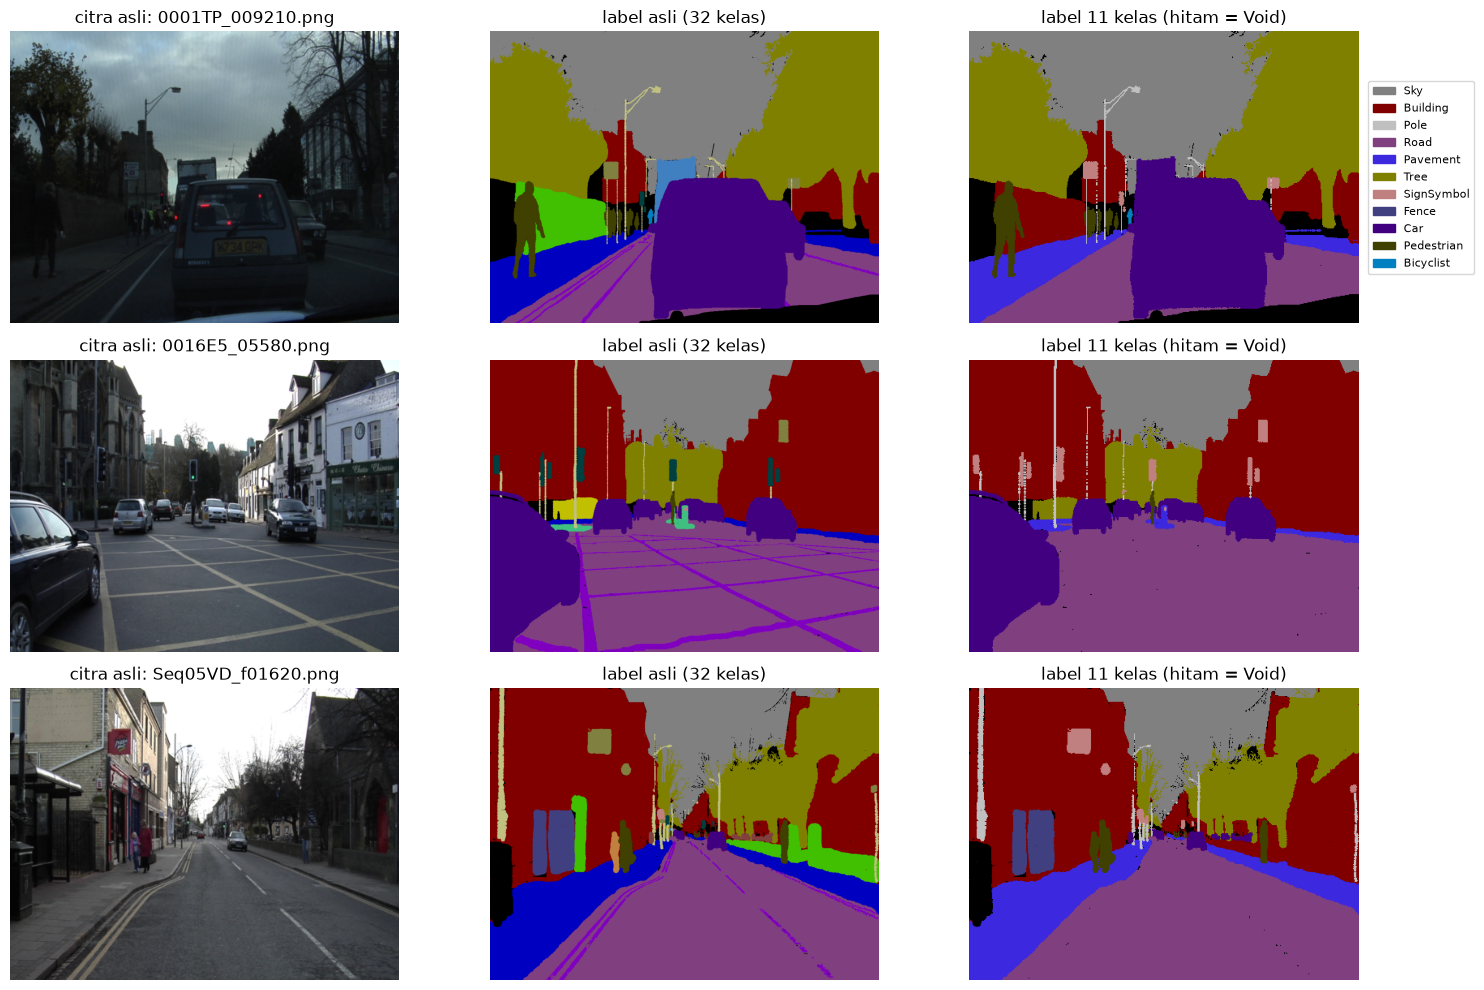

In [6]:
# contoh data: citra asli | label asli (32 kelas) | label setelah dipetakan ke 11 kelas
img_paths, lbl_paths = list_pairs('train')
fig, ax = plt.subplots(3, 3, figsize=(16, 10))
for r, k in enumerate([0, 150, 300]):
    ax[r, 0].imshow(train_ds.images[k]);    ax[r, 0].set_title('citra asli: ' + os.path.basename(img_paths[k]))
    ax[r, 1].imshow(Image.open(lbl_paths[k])); ax[r, 1].set_title('label asli (32 kelas)')
    ax[r, 2].imshow(label_to_color(train_ds.labels[k])); ax[r, 2].set_title('label 11 kelas (hitam = Void)')
for a in ax.flat:
    a.axis('off')
add_legend(ax[0, 2])
plt.tight_layout(); plt.show()

## 4. Bobot kelas (median frequency balancing)
Piksel Road/Sky/Building jauh lebih banyak daripada Pole/SignSymbol/Bicyclist. Tanpa pembobotan,
model cenderung mengabaikan kelas kecil. Bobot kelas c = median(freq) / freq(c), dengan
freq(c) = jumlah piksel kelas c / jumlah piksel citra yang memuat kelas c (cara yang sama dengan contoh MathWorks).

In [7]:
pixel_count = np.zeros(NUM_CLASSES)   # jumlah piksel tiap kelas
image_pixels = np.zeros(NUM_CLASSES)  # jumlah piksel citra yang memuat kelas tsb
for lbl in train_ds.labels:
    for c in range(NUM_CLASSES):
        n = np.sum(lbl == c)
        if n > 0:
            pixel_count[c] += n
            image_pixels[c] += lbl.size

freq = pixel_count / image_pixels
class_weights = np.median(freq) / freq
print(pd.DataFrame({'kelas': CLASS_NAMES, 'frekuensi': freq.round(4), 'bobot': class_weights.round(3)}))

         kelas  frekuensi  bobot
0          Sky     0.1517  0.285
1     Building     0.2418  0.179
2         Pole     0.0104  4.146
3         Road     0.3050  0.142
4     Pavement     0.0765  0.566
5         Tree     0.1197  0.362
6   SignSymbol     0.0120  3.596
7        Fence     0.0291  1.486
8          Car     0.0433  1.000
9   Pedestrian     0.0075  5.765
10   Bicyclist     0.0095  4.561


## 5. Model pretrained + transfer learning
DeepLabV3 dengan backbone **ResNet-50**, bobot pretrained COCO (21 kelas VOC).
Sama seperti model MobileNetV3: layer klasifikasi terakhir diganti menjadi 11 kelas, cabang auxiliary
dibuang, lalu **seluruh jaringan di-fine-tune** dengan data CamVid.

In [8]:
model = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)

# transfer learning: layer terakhir (conv 1x1, 21 kelas VOC) diganti jadi 11 kelas CamVid
model.classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)
model.aux_classifier = None      # cabang auxiliary tidak dipakai
model = model.to(device)
print(f'jumlah parameter: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} juta')
print(model.classifier)

jumlah parameter: 39.6 juta
DeepLabHead(
  (0): ASPP(
    (convs): ModuleList(
      (0): Sequential(
        (0): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
      )
      (1): ASPPConv(
        (0): Conv2d(2048, 256, kernel_size=(3, 3), stride=(1, 1), padding=(12, 12), dilation=(12, 12), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
      )
      (2): ASPPConv(
        (0): Conv2d(2048, 256, kernel_size=(3, 3), stride=(1, 1), padding=(24, 24), dilation=(24, 24), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
      )
      (3): ASPPConv(
        (0): Conv2d(2048, 256, kernel_size=(3, 3), stride=(1, 1), padding=(36, 36), dilation=(36, 36), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momen

## 6. Training
Metrik: **IoU** tiap kelas = TP / (TP + FP + FN), **mIoU** = rata-rata IoU 11 kelas,
**pixel accuracy** = piksel benar / semua piksel berlabel. Model dengan mIoU validasi terbaik yang disimpan.

Training memakai **mixed precision** (`torch.autocast` float16 + `GradScaler`): forward/backward dihitung
dalam float16 sehingga memori aktivasi kira-kira setengahnya. Tanpa ini ResNet-50 dengan batch 8 tidak muat
di GPU 8 GB. Evaluasi tetap float32.

Bobot disimpan dalam **float16** supaya file model sekitar 76 MB (float32: 152 MB, melebihi batas file
GitHub 100 MB). Saat dimuat, bobot otomatis kembali menjadi float32 (`load_state_dict` menyalin ke
parameter float32). Pembulatan ke float16 tidak mengubah hasil: mIoU test float32 dan float16 sama
(0,71635), hanya 0,02% piksel yang prediksinya berubah.

In [9]:
def evaluate(model, loader):
    # confusion matrix seluruh data -> IoU tiap kelas, mIoU, pixel accuracy (float32)
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=device)
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)['out'].argmax(1)
            valid = y != IGNORE
            # baris = label sebenarnya, kolom = prediksi
            idx = y[valid] * NUM_CLASSES + pred[valid]
            conf += torch.bincount(idx, minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)
    conf = conf.cpu().numpy().astype(np.float64)
    tp = np.diag(conf)
    iou = tp / np.maximum(conf.sum(0) + conf.sum(1) - tp, 1)
    acc = tp.sum() / conf.sum()
    return iou, iou.mean(), acc


def save_checkpoint(path):
    # format sama dengan camvid_train.ipynb, 'arch' dipakai camvid_predict.py untuk memilih arsitektur.
    # tensor float disimpan float16 (file ~76 MB, bukan 152 MB), tensor integer (num_batches_tracked) tetap
    torch.save({'arch': 'deeplabv3_resnet50',
                'state_dict': {k: (v.half() if v.is_floating_point() else v).cpu()
                               for k, v in model.state_dict().items()},
                'class_names': CLASS_NAMES,
                'palette': PALETTE,
                'input_size': list(IMG_SIZE),
                'mean': MEAN,
                'std': STD}, path)

In [9]:
weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=weights, ignore_index=IGNORE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)   # lr turun pelan ke 0
scaler = torch.amp.GradScaler('cuda')   # mencegah gradien float16 terlalu kecil jadi 0

history = {'loss': [], 'val_miou': [], 'val_acc': []}
best_miou, best_epoch = -1, 0
t_all = time.time()
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    total_loss = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = criterion(model(x)['out'], y)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
    scheduler.step()

    _, val_miou, val_acc = evaluate(model, val_dl)
    history['loss'].append(total_loss / len(train_dl))
    history['val_miou'].append(val_miou)
    history['val_acc'].append(val_acc)

    note = ''
    if val_miou > best_miou:
        best_miou, best_epoch = val_miou, epoch
        save_checkpoint(OUT_PATH)
        note = '  <- disimpan'
    print(f'epoch {epoch:2d} | loss {history["loss"][-1]:.3f} | val mIoU {val_miou:.3f} '
          f'| val acc {val_acc:.3f} | {time.time() - t0:.0f}s{note}')
    if epoch == 1:
        print(f'memori GPU puncak: {torch.cuda.max_memory_allocated() / 2**30:.2f} GB')

print(f'\ntraining selesai {(time.time() - t_all) / 60:.1f} menit, '
      f'terbaik epoch {best_epoch} (val mIoU {best_miou:.3f})')
pd.DataFrame(history).rename_axis('epoch').to_csv(os.path.join(CMP_DIR, 'history_r50.csv'))

epoch  1 | loss 1.093 | val mIoU 0.468 | val acc 0.772 | 21s  <- disimpan
memori GPU puncak: 3.48 GB


epoch  2 | loss 0.590 | val mIoU 0.577 | val acc 0.863 | 21s  <- disimpan


epoch  3 | loss 0.454 | val mIoU 0.609 | val acc 0.868 | 21s  <- disimpan


epoch  4 | loss 0.358 | val mIoU 0.641 | val acc 0.892 | 21s  <- disimpan


epoch  5 | loss 0.309 | val mIoU 0.644 | val acc 0.895 | 22s  <- disimpan


epoch  6 | loss 0.298 | val mIoU 0.638 | val acc 0.881 | 21s


... (40 outputs left out)

epoch 47 | loss 0.082 | val mIoU 0.749 | val acc 0.938 | 28s


epoch 48 | loss 0.082 | val mIoU 0.750 | val acc 0.938 | 28s  <- disimpan


epoch 49 | loss 0.082 | val mIoU 0.749 | val acc 0.938 | 28s


epoch 50 | loss 0.082 | val mIoU 0.749 | val acc 0.938 | 28s

training selesai 21.9 menit, terbaik epoch 48 (val mIoU 0.750)


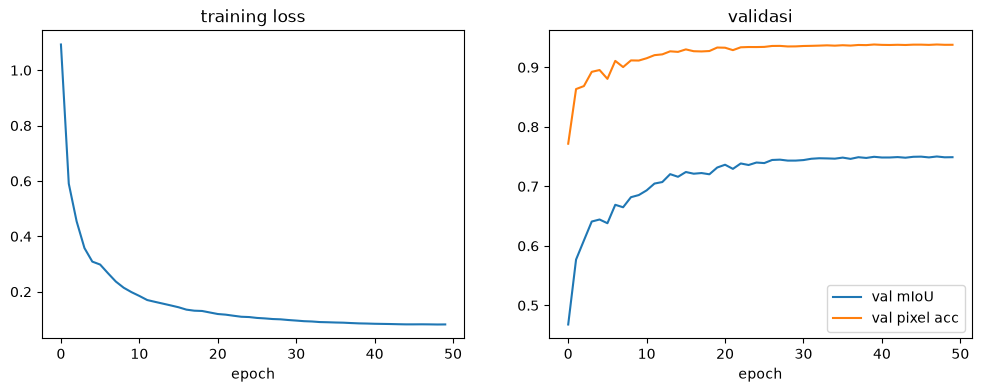

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['loss']);     ax[0].set_title('training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(history['val_miou'], label='val mIoU')
ax[1].plot(history['val_acc'], label='val pixel acc')
ax[1].set_title('validasi'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.show()

## 7. Evaluasi pada data test

In [10]:
# pakai model terbaik (mIoU validasi tertinggi), bukan model epoch terakhir
# (bobot float16 di file otomatis jadi float32 saat dimuat ke model)
ckpt = torch.load(OUT_PATH, map_location=device)
model.load_state_dict(ckpt['state_dict'])

test_iou, test_miou, test_acc = evaluate(model, test_dl)
print(pd.DataFrame({'kelas': CLASS_NAMES, 'IoU': test_iou.round(3)}).to_string(index=False))
print(f'\nmIoU test     : {test_miou:.3f}')
print(f'pixel acc test: {test_acc:.3f}')

     kelas   IoU
       Sky 0.918
  Building 0.859
      Pole 0.326
      Road 0.959
  Pavement 0.825
      Tree 0.794
SignSymbol 0.536
     Fence 0.640
       Car 0.832
Pedestrian 0.553
 Bicyclist 0.637

mIoU test     : 0.716
pixel acc test: 0.926


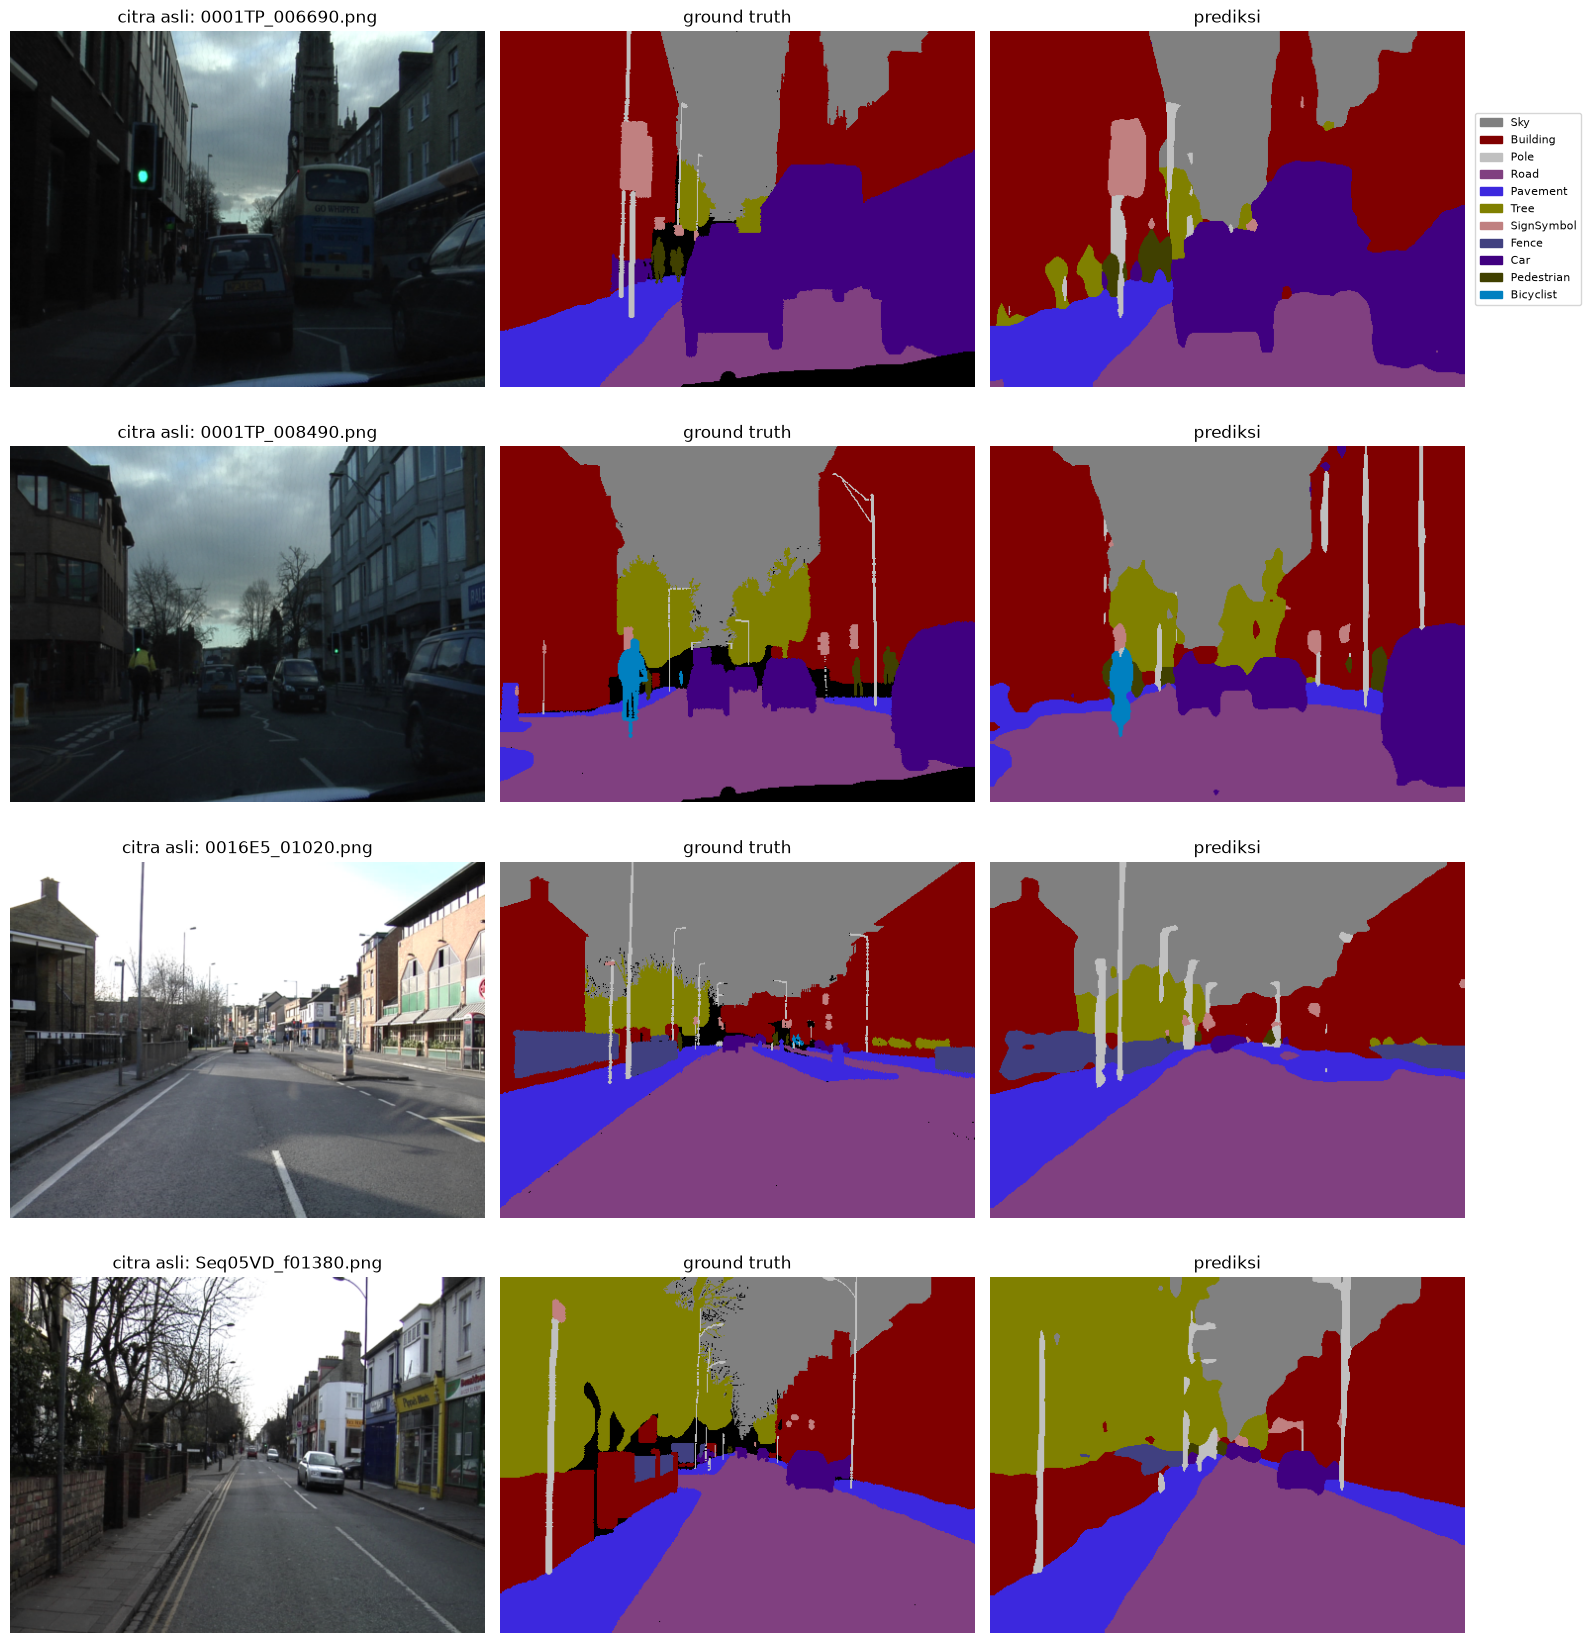

In [11]:
# contoh hasil: citra asli | ground truth | prediksi
model.eval()
picks = [0, 60, 120, 200]
fig, ax = plt.subplots(len(picks), 3, figsize=(16, 4.2 * len(picks)))
test_imgs, _ = list_pairs('test')
for r, k in enumerate(picks):
    x, _ = test_ds[k]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(device))['out'].argmax(1)[0].cpu().numpy().astype(np.uint8)
    ax[r, 0].imshow(test_ds.images[k]);              ax[r, 0].set_title('citra asli: ' + os.path.basename(test_imgs[k]))
    ax[r, 1].imshow(label_to_color(test_ds.labels[k])); ax[r, 1].set_title('ground truth')
    ax[r, 2].imshow(label_to_color(pred));            ax[r, 2].set_title('prediksi')
for a in ax.flat:
    a.axis('off')
add_legend(ax[0, 2])
plt.tight_layout(); plt.show()

## 8. Perbandingan dengan DeepLabV3 + MobileNetV3
Kedua model dievaluasi dengan cara yang sama (float32, 232 citra test, ukuran 360x480):
IoU tiap kelas, mIoU, pixel accuracy, jumlah parameter, ukuran file, dan waktu inferensi per citra
(GPU dan CPU, rata-rata setelah pemanasan, tanpa waktu memuat model).
Model MobileNetV3 dibaca dari `model/camvid_deeplabv3_mbv3.pth` (hasil `camvid_train.ipynb`)
memakai `load_model` dari `camvid_predict.py`, yaitu fungsi yang sama dengan yang dipanggil GUI.

In [12]:
from camvid_predict import load_model

MBV3_PATH = os.path.join('model', 'camvid_deeplabv3_mbv3.pth')
assert os.path.isfile(MBV3_PATH), 'jalankan camvid_train.ipynb dulu (model MobileNetV3 belum ada)'


def time_inference(net, x, dev, reps):
    # rata-rata waktu forward 1 citra (detik), setelah 3x pemanasan
    net = net.to(dev).eval()
    x = x.to(dev)
    with torch.no_grad():
        for _ in range(3):
            net(x)
        if dev.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(reps):
            net(x)
        if dev.type == 'cuda':
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps


x1 = test_ds[0][0].unsqueeze(0)
nets = {'MobileNetV3': load_model(MBV3_PATH)[0], 'ResNet-50': load_model(OUT_PATH)[0]}
paths = {'MobileNetV3': MBV3_PATH, 'ResNet-50': OUT_PATH}

per_class = {'kelas': CLASS_NAMES + ['mIoU', 'pixel acc']}
summary = []
for name, net in nets.items():
    net = net.to(device)
    iou, miou, acc = evaluate(net, test_dl)
    per_class[name] = list(iou.round(3)) + [round(miou, 3), round(acc, 3)]
    summary.append({'model': f'DeepLabV3 + {name}',
                    'parameter (juta)': round(sum(p.numel() for p in net.parameters()) / 1e6, 1),
                    'ukuran file (MB)': round(os.path.getsize(paths[name]) / 2**20, 1),
                    'mIoU test': round(miou, 3),
                    'pixel acc test': round(acc, 3),
                    'inferensi GPU (ms/citra)': round(time_inference(net, x1, device, 50) * 1000, 1),
                    'inferensi CPU (ms/citra)': round(time_inference(net, x1, torch.device('cpu'), 5) * 1000, 1)})
    nets[name] = net.to(device)

per_class = pd.DataFrame(per_class)
per_class['selisih'] = (per_class['ResNet-50'] - per_class['MobileNetV3']).round(3)
summary = pd.DataFrame(summary)
per_class.to_csv(os.path.join(CMP_DIR, 'metrics.csv'), index=False)
summary.to_csv(os.path.join(CMP_DIR, 'summary.csv'), index=False)
print(per_class.to_string(index=False))
print()
print(summary.to_string(index=False))

     kelas  MobileNetV3  ResNet-50  selisih
       Sky        0.897      0.918    0.021
  Building        0.807      0.859    0.052
      Pole        0.184      0.326    0.142
      Road        0.931      0.959    0.028
  Pavement        0.744      0.825    0.081
      Tree        0.765      0.794    0.029
SignSymbol        0.377      0.536    0.159
     Fence        0.548      0.640    0.092
       Car        0.772      0.832    0.060
Pedestrian        0.421      0.553    0.132
 Bicyclist        0.556      0.637    0.081
      mIoU        0.637      0.716    0.079
 pixel acc        0.893      0.926    0.033

                  model  parameter (juta)  ukuran file (MB)  mIoU test  pixel acc test  inferensi GPU (ms/citra)  inferensi CPU (ms/citra)
DeepLabV3 + MobileNetV3              11.0              42.3      0.637           0.893                       4.3                      47.3
  DeepLabV3 + ResNet-50              39.6              75.8      0.716           0.926                   

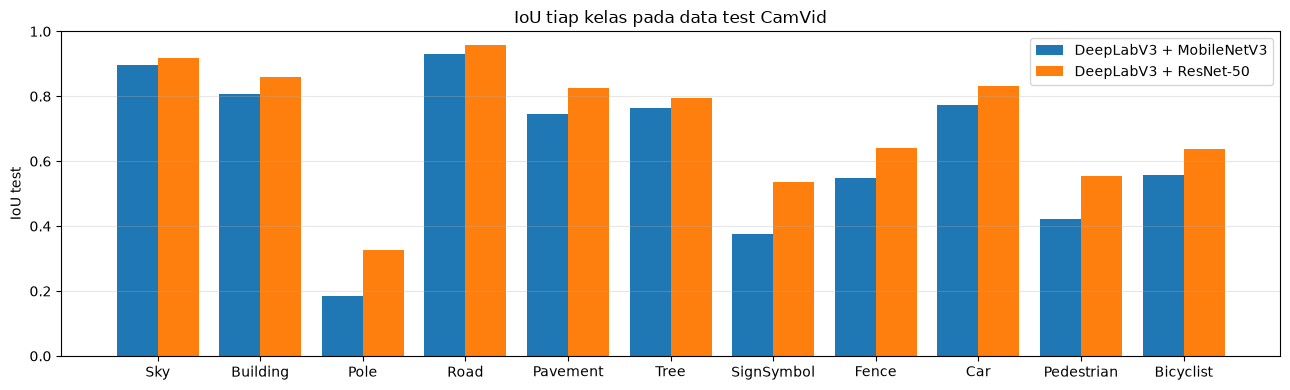

In [13]:
# IoU tiap kelas kedua model
xs = np.arange(NUM_CLASSES)
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(xs - 0.2, per_class['MobileNetV3'][:NUM_CLASSES], 0.4, label='DeepLabV3 + MobileNetV3')
ax.bar(xs + 0.2, per_class['ResNet-50'][:NUM_CLASSES], 0.4, label='DeepLabV3 + ResNet-50')
ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel('IoU test'); ax.set_ylim(0, 1); ax.legend(); ax.grid(axis='y', alpha=0.3)
ax.set_title('IoU tiap kelas pada data test CamVid')
plt.tight_layout(); plt.savefig(os.path.join(CMP_DIR, 'iou_per_class.png'), dpi=110); plt.show()

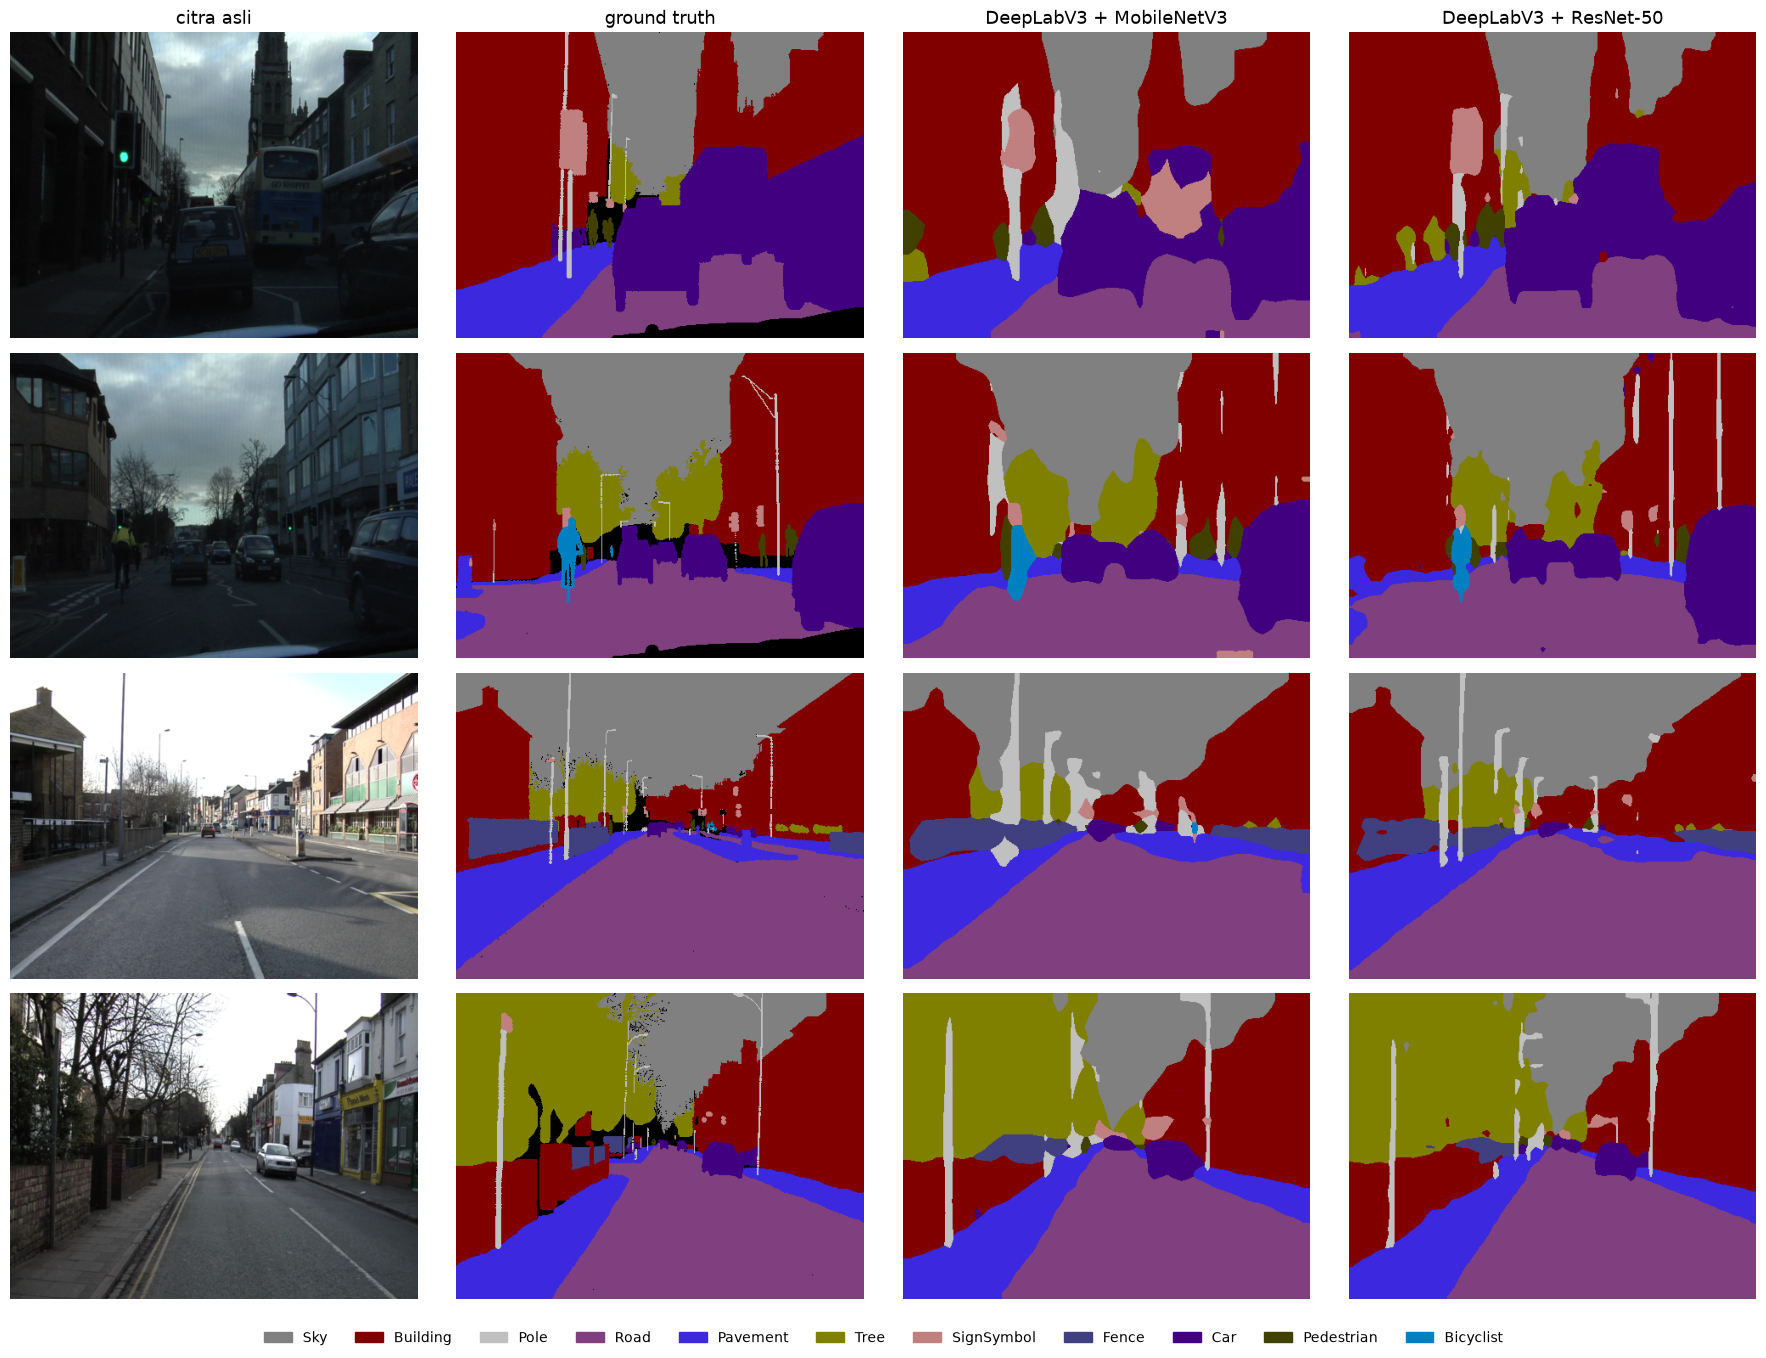

In [14]:
# contoh hasil: citra asli | ground truth | MobileNetV3 | ResNet-50
picks = [0, 60, 120, 200]
fig, ax = plt.subplots(len(picks), 4, figsize=(18, 3.4 * len(picks)))
titles = ['citra asli', 'ground truth', 'DeepLabV3 + MobileNetV3', 'DeepLabV3 + ResNet-50']
for r, k in enumerate(picks):
    x, _ = test_ds[k]
    preds = []
    with torch.no_grad():
        for net in nets.values():
            net.eval()
            preds.append(net(x.unsqueeze(0).to(device))['out'].argmax(1)[0].cpu().numpy().astype(np.uint8))
    panels = [test_ds.images[k], label_to_color(test_ds.labels[k])] + [label_to_color(p) for p in preds]
    for c in range(4):
        ax[r, c].imshow(panels[c]); ax[r, c].axis('off')
        if r == 0:
            ax[r, c].set_title(titles[c], fontsize=13)
patches = [mpatches.Patch(color=np.array(c) / 255, label=n) for n, c in zip(CLASS_NAMES, PALETTE)]
fig.legend(handles=patches, loc='lower center', ncol=NUM_CLASSES, fontsize=10, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(os.path.join(CMP_DIR, 'examples.png'), dpi=110); plt.show()

## 9. Simpan model
- Model sudah tersimpan di `model/camvid_deeplabv3_r50.pth` (sekitar 76 MB, bobot float16). File ini bisa langsung
  dipakai GUI: isi path model di panel Semantik CNN dengan file tersebut, `camvid_predict.py`
  memilih arsitektur dari field `arch` di checkpoint.
- Hasil perbandingan (`metrics.csv`, `summary.csv`, `iou_per_class.png`, `examples.png`, `history_r50.csv`)
  ada di `results/semantic_compare/`.